# EDA dan Pembersihan Data · Prakiraan PM2.5 Bandung (Kasus 06)

**Tujuan notebook:** memahami data sensor kualitas udara dari lima stasiun, menemukan dan membersihkan masalah data,
membuat target PM2.5 tiga jam ke depan, membagi data berdasarkan waktu, lalu menghitung *baseline persistence*.

**Keluaran notebook:** `data/clean.csv` (data bersih) dan angka *baseline* pada data *train* dan *validation*.
Data *test* (Mei–Juni 2026) **tidak dievaluasi di sini**; data itu baru dibuka sekali di akhir, bersama model final.

In [1]:
# Menentukan folder proyek (hanya dari komputer lokal, tidak mengunduh apa pun).
# Notebook ini disimpan di notebooks/, jadi folder proyek biasanya satu tingkat di atasnya.
# Jika dijalankan dari tempat lain, isi PROJECT_DIR secara manual, misalnya:
# PROJECT_DIR = r"C:\Users\pf3rz\Documents\pm25-forecast-bandung"
import os
from pathlib import Path

PROJECT_DIR = None

kandidat = [Path(PROJECT_DIR)] if PROJECT_DIR else [Path.cwd(), Path.cwd().parent]
for folder in kandidat:
    if (folder / "data" / "raw.csv").exists():
        os.chdir(folder)
        break
else:
    raise FileNotFoundError(
        "data/raw.csv tidak ditemukan di " + ", ".join(str(k) for k in kandidat)
        + ". Jalankan notebook dari folder notebooks/ di dalam folder proyek, atau isi PROJECT_DIR."
    )

print("folder kerja:", Path.cwd())

folder kerja: /tmp/pm25-forecast-bandung


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RANDOM_STATE = 42
AMBANG_TIDAK_SEHAT = 55  # µg/m³, kategori "tidak sehat" menurut brief
URUTAN_STASIUN = ["Dago", "Soekarno-Hatta", "Cibeureum", "Antapani", "Ujungberung"]

df = pd.read_csv("data/raw.csv")
print(f"{len(df):,} baris, {df.shape[1]} kolom")
df.head()

87,650 baris, 8 kolom


,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00,Dago,26.9,19.1,89.0,0.9,112.0,0.0
1,2024-07-01 01:00,Dago,25.3,18.4,86.0,1.2,158.0,0.0
2,2024-07-01 02:00,Dago,27.8,17.3,95.0,0.8,97.0,0.0
3,2024-07-01 03:00,Dago,26.0,16.6,89.0,0.8,66.0,0.0
4,2024-07-01 04:00,Dago,26.6,16.0,91.0,0.1,104.0,0.0


## 1. Data Understanding

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87650 entries, 0 to 87649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   waktu               87650 non-null  str    
 1   stasiun             87650 non-null  str    
 2   pm25_ugm3           87506 non-null  float64
 3   suhu_C              87506 non-null  float64
 4   kelembaban_pct      87506 non-null  float64
 5   kecepatan_angin_ms  86773 non-null  float64
 6   arah_angin_deg      87650 non-null  float64
 7   curah_hujan_mm      87650 non-null  float64
dtypes: float64(6), str(2)
memory usage: 5.3 MB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pm25_ugm3,87506.0,23.99,47.18,-999.0,17.2,24.0,32.6,128.4
suhu_C,87506.0,23.06,3.67,12.0,19.8,23.1,26.3,31.9
kelembaban_pct,87506.0,80.84,9.85,51.0,73.0,81.0,89.0,100.0
kecepatan_angin_ms,86773.0,1.95,1.10,0.1,1.0,2.0,2.7,7.9
arah_angin_deg,87650.0,179.37,84.51,0.0,110.0,178.0,248.0,360.0
curah_hujan_mm,87650.0,0.38,1.52,0.0,0.0,0.0,0.0,24.9


In [5]:
print("jumlah variasi nama stasiun:", df["stasiun"].nunique())
# repr() memperlihatkan spasi di akhir nama yang tidak terlihat oleh print biasa
df["stasiun"].map(repr).value_counts()

jumlah variasi nama stasiun: 16


stasiun
'Dago'               17025
'Cibeureum'          17011
'Soekarno-Hatta'     16997
'Ujungberung'        16995
'Antapani'           16987
'Ujung Berung'         286
'antapani'             285
'ujungberung'          264
'Cibeureum '           260
'dago '                259
'ANTAPANI'             258
'cibeureum'            255
'DAGO'                 243
'Soekarno-Hatta '      177
'Soekarno Hatta'       175
'SOETTA'               173
Name: count, dtype: int64

**Pembahasan Bagian 1.** Data berisi **87.650 baris** dan 8 kolom, mencakup 1 Juli 2024 sampai 30 Juni 2026. Lima stasiun × 17.520 jam seharusnya menghasilkan 87.600 baris, jadi kelebihan 50 baris sudah menandakan ada data ganda. Ada tiga hal yang langsung terlihat:

- Kolom `stasiun` memiliki **16 variasi penulisan** untuk 5 stasiun: huruf besar/kecil, spasi di akhir nama (`'dago '`), "Ujung Berung", "Soekarno Hatta", dan singkatan "SOETTA".
- Nilai minimum PM2.5 adalah **-999**, jelas bukan konsentrasi melainkan kode khusus. Kode inilah yang membuat simpangan baku PM2.5 membengkak menjadi 47 µg/m³.
- Kolom `waktu` masih bertipe teks dan tidak memiliki keterangan zona waktu.

## 2. Data Quality

In [6]:
# Nilai kosong per kolom
pd.DataFrame({
    "jumlah_kosong": df.isnull().sum(),
    "persen_kosong": (df.isnull().mean() * 100).round(3),
}).sort_values("jumlah_kosong", ascending=False)

,jumlah_kosong,persen_kosong
kecepatan_angin_ms,877,1.001
suhu_C,144,0.164
kelembaban_pct,144,0.164
pm25_ugm3,144,0.164
waktu,0,0.000
stasiun,0,0.000
arah_angin_deg,0,0.000
curah_hujan_mm,0,0.000


In [7]:
# Duplikat: baris yang persis sama, dan pasangan (waktu, stasiun) yang muncul lebih dari sekali
print("baris persis sama:", df.duplicated().sum())
print("pasangan waktu-stasiun berulang:", df.duplicated(subset=["waktu", "stasiun"]).sum())

baris persis sama: 398
pasangan waktu-stasiun berulang: 404


In [8]:
# Nilai tidak wajar: sentinel -999 dan PM2.5 tepat nol
numeric_cols = df.select_dtypes(include=np.number).columns
pd.DataFrame({
    "min": df[numeric_cols].min(),
    "max": df[numeric_cols].max(),
    "negatif": (df[numeric_cols] < 0).sum(),
    "sama_-999": (df[numeric_cols] == -999).sum(),
    "sama_0": (df[numeric_cols] == 0).sum(),
})

,min,max,negatif,sama_-999,sama_0
pm25_ugm3,-999.0,128.4,173,173,88
suhu_C,12.0,31.9,0,0,0
kelembaban_pct,51.0,100.0,0,0,0
kecepatan_angin_ms,0.1,7.9,0,0,0
arah_angin_deg,0.0,360.0,0,0,29
curah_hujan_mm,0.0,24.9,0,0,78459


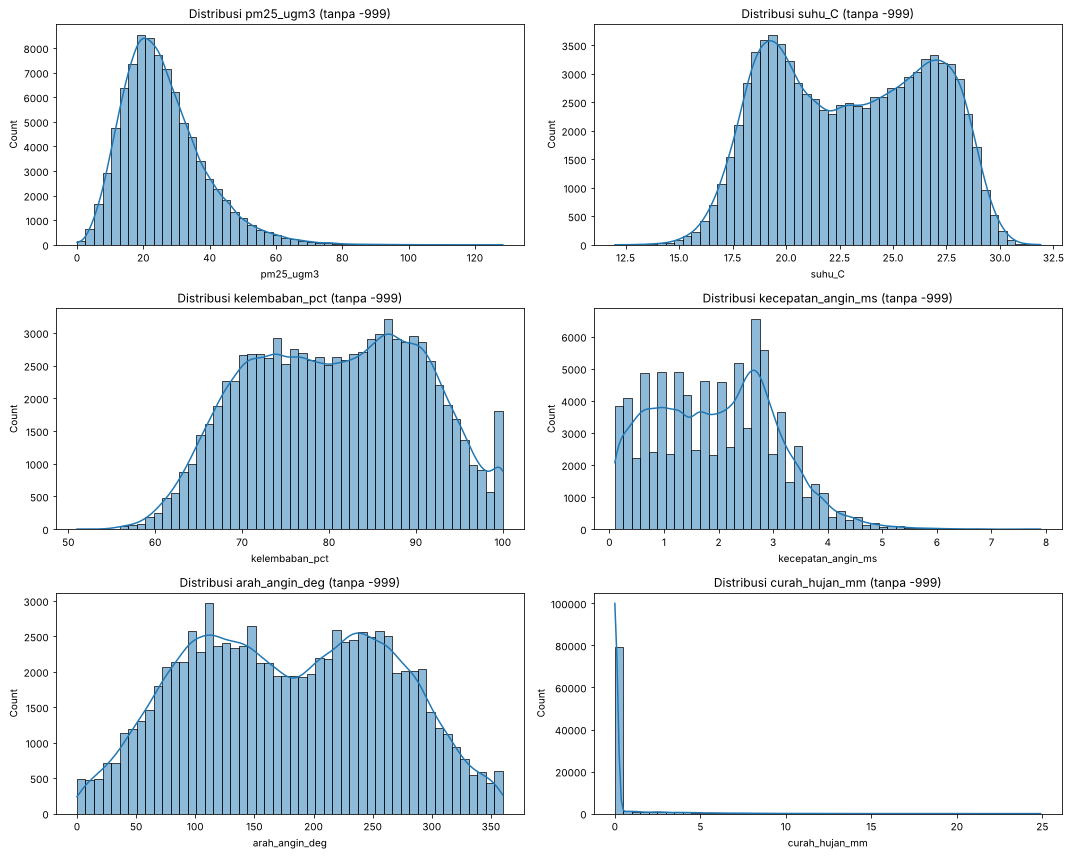

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, col in zip(axes.flatten(), numeric_cols):
    # -999 dibuang dulu agar bentuk distribusi terlihat
    sns.histplot(df.loc[df[col] != -999, col], bins=50, kde=True, ax=ax)
    ax.set_title(f"Distribusi {col} (tanpa -999)")
plt.tight_layout()
plt.show()

**Pembahasan Bagian 2.** Ada lima jenis masalah kualitas data:

1. **Nilai kosong** sedikit: 144 baris (0,16%) untuk PM2.5, suhu, dan kelembapan, serta 877 baris (1%) untuk kecepatan angin.
2. **Duplikat:** 398 baris persis sama. Pasangan waktu-stasiun yang berulang berjumlah 404. Jadi selain duplikat persis, ada pasangan yang waktunya sama tetapi isinya berbeda. Sumbernya diselidiki di bagian 2.1.
3. **Sentinel -999** pada PM2.5: 173 baris.
4. **PM2.5 tepat 0:** 88 baris. Nilai ini lolos dari pemeriksaan "tidak negatif", padahal udara perkotaan hampir mustahil benar-benar bebas partikel.
5. Nilai **0 pada `curah_hujan_mm`** wajar (tidak hujan), begitu pula 0 pada `arah_angin_deg` (arah utara, sama dengan 360°).

Histogram tanpa -999 memperlihatkan PM2.5 condong ke kanan: kebanyakan jam berada di 15–35 µg/m³, dengan ekor panjang sampai sekitar 128 µg/m³.

### 2.1 Pemeriksaan zona waktu

Brief menyebut kolom `waktu` *seharusnya* dalam WIB, jadi perlu dibuktikan. Caranya: suhu udara selalu paling tinggi
pada siang hari (sekitar pukul 14–15 WIB). Jika suatu stasiun pada bulan tertentu memiliki jam puncak suhu yang jauh
berbeda, waktu di stasiun itu kemungkinan tidak dicatat dalam WIB.

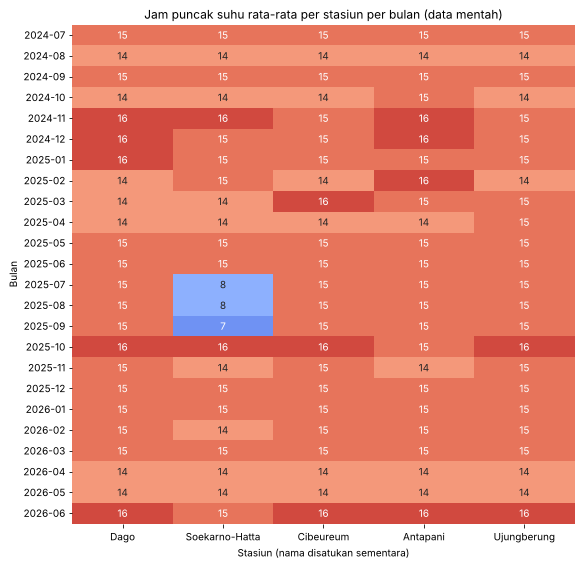

In [10]:
cek = df.copy()
peta_sementara = {"dago": "Dago", "soekarnohatta": "Soekarno-Hatta", "soetta": "Soekarno-Hatta",
                  "cibeureum": "Cibeureum", "antapani": "Antapani", "ujungberung": "Ujungberung"}
cek["stasiun_norm"] = (cek["stasiun"].str.strip().str.lower()
                       .str.replace(r"[\s-]+", "", regex=True).map(peta_sementara))
cek["waktu"] = pd.to_datetime(cek["waktu"])
cek["bulan"] = cek["waktu"].dt.to_period("M").astype(str)
cek["jam"] = cek["waktu"].dt.hour

def jam_puncak_suhu(data, kolom_stasiun):
    rata = data.groupby([kolom_stasiun, "bulan", "jam"])["suhu_C"].mean()
    return rata.groupby(level=[0, 1]).idxmax().map(lambda x: x[2]).unstack(0)

puncak_sebelum = jam_puncak_suhu(cek, "stasiun_norm")[URUTAN_STASIUN]

plt.figure(figsize=(9, 9))
sns.heatmap(puncak_sebelum, annot=True, fmt="d", cmap="coolwarm", vmin=5, vmax=17, cbar=False)
plt.title("Jam puncak suhu rata-rata per stasiun per bulan (data mentah)")
plt.xlabel("Stasiun (nama disatukan sementara)")
plt.ylabel("Bulan")
plt.show()

**Pembahasan Bagian 2.1.** Hampir semua sel berada di pukul **14–16**, sesuai pola suhu harian di WIB. Pengecualiannya hanya **Soekarno-Hatta pada Juli, Agustus, dan September 2025**, dengan puncak di pukul **07–08**, tepat 7 jam lebih awal. Itu sama dengan selisih WIB dan UTC.

Kesimpulannya, selama tiga bulan itu sensor Soekarno-Hatta mencatat waktu dalam **UTC**. Kesalahan ini juga menjelaskan pasangan waktu-stasiun yang berulang dengan isi berbeda pada 2025-06-30 pukul 17:00–23:00 (bagian 2): jam-jam UTC di awal periode bertabrakan dengan jam WIB yang sudah ada. Jika tidak dikoreksi, fitur jam, fitur *lag*, dan target di stasiun paling tercemar akan bergeser 7 jam selama tiga bulan.

## 3. Data Cleaning

Setiap langkah dicatat ke `log_masalah` agar tabel masalah data untuk README dan laporan terbentuk otomatis.

In [11]:
df_clean = df.copy()
log_masalah = []

def catat(masalah, jumlah, penanganan, alasan):
    log_masalah.append({"masalah": masalah, "jumlah_baris": int(jumlah),
                        "penanganan": penanganan, "alasan": alasan})

### 3.1 Standarisasi nama stasiun

In [12]:
station_mapping = {
    "dago": "Dago",
    "soekarnohatta": "Soekarno-Hatta",
    "soetta": "Soekarno-Hatta",
    "cibeureum": "Cibeureum",
    "antapani": "Antapani",
    "ujungberung": "Ujungberung",
}

nama_asli = df_clean["stasiun"].copy()
df_clean["stasiun"] = (
    df_clean["stasiun"].astype("string").str.strip().str.lower()
    .str.replace(r"[\s-]+", "", regex=True)
    .map(station_mapping)
)
assert df_clean["stasiun"].notna().all(), "ada nama stasiun yang belum dipetakan"

catat("Variasi penulisan nama stasiun", (nama_asli != df_clean["stasiun"]).sum(),
      "dinormalisasi ke 5 nama baku", "satu stasiun ditulis dengan 16 cara (huruf besar, spasi, singkatan SOETTA)")
df_clean["stasiun"].value_counts()

stasiun
Ujungberung       17545
Antapani          17530
Dago              17527
Cibeureum         17526
Soekarno-Hatta    17522
Name: count, dtype: int64

### 3.2 Konversi waktu dan penghapusan duplikat persis

In [13]:
df_clean["waktu"] = pd.to_datetime(df_clean["waktu"], errors="coerce")
print("waktu tidak valid:", df_clean["waktu"].isna().sum())
print("rentang:", df_clean["waktu"].min(), "sampai", df_clean["waktu"].max())

n_dup = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()   # indeks asli dipertahankan untuk langkah 3.3
catat("Baris duplikat persis", n_dup, "dihapus (drop_duplicates)", "baris yang sama tercatat dua kali saat ekspor")
print("duplikat persis dihapus:", n_dup, "| sisa baris:", len(df_clean))

waktu tidak valid: 0
rentang: 2024-07-01 00:00:00 sampai 2026-06-30 23:00:00
duplikat persis dihapus: 398 | sisa baris: 87252


### 3.3 Koreksi periode UTC di Soekarno-Hatta

Pada data Soekarno-Hatta yang masih dalam **urutan baris asli file**, ada satu titik ketika waktu tiba-tiba *mundur*
(dari 2025-06-30 23:00 kembali ke 2025-06-30 17:00). Di titik itulah pencatatan mulai memakai UTC:
17:00 UTC sama dengan 00:00 WIB tanggal 1 Juli. Periode ini berakhir ketika jam "mengejar" kembali, ditandai
loncatan 8 jam (7 jam selisih zona waktu ditambah 1 jam normal) dari 2025-09-30 16:00 ke 2025-10-01 00:00.

Baris-baris pada periode ini **digeser +7 jam**, bukan dibuang, karena isinya valid; hanya label jamnya yang salah.

In [14]:
sh = df_clean[df_clean["stasiun"] == "Soekarno-Hatta"]      # urutan baris asli file
selisih = sh["waktu"].diff()

titik_mundur = sh.index[selisih < pd.Timedelta(0)]
assert len(titik_mundur) == 1, "seharusnya hanya ada satu titik waktu mundur"
awal_utc = titik_mundur[0]

titik_kejar = sh.index[(sh.index > awal_utc) & (selisih == pd.Timedelta(hours=8))]
akhir_utc = sh.index[sh.index.get_loc(titik_kejar[0]) - 1]   # baris tepat sebelum loncatan 8 jam

segmen_utc = (df_clean["stasiun"] == "Soekarno-Hatta") & df_clean.index.to_series().between(awal_utc, akhir_utc)
print("awal periode UTC :", df_clean.loc[awal_utc, "waktu"])
print("akhir periode UTC:", df_clean.loc[akhir_utc, "waktu"])
print("jumlah baris     :", segmen_utc.sum())

df_clean.loc[segmen_utc, "waktu"] += pd.Timedelta(hours=7)

print("pasangan waktu-stasiun berulang setelah koreksi:",
      df_clean.duplicated(subset=["waktu", "stasiun"]).sum())
catat("Waktu Soekarno-Hatta Jul–Sep 2025 tercatat dalam UTC", segmen_utc.sum(),
      "digeser +7 jam ke WIB", "jam puncak suhu bergeser ke pukul 07–08; menimbulkan 7 pasangan waktu ganda dan celah 7 jam")

awal periode UTC : 2025-06-30 17:00:00
akhir periode UTC: 2025-09-30 16:00:00
jumlah baris     : 2196
pasangan waktu-stasiun berulang setelah koreksi: 0


In [15]:
# Bukti: jam puncak suhu Soekarno-Hatta sebelum dan sesudah koreksi
sesudah = df_clean.assign(bulan=df_clean["waktu"].dt.to_period("M").astype(str), jam=df_clean["waktu"].dt.hour)
puncak_sesudah = jam_puncak_suhu(sesudah, "stasiun")

bandingan = pd.DataFrame({
    "sebelum": puncak_sebelum["Soekarno-Hatta"],
    "sesudah": puncak_sesudah["Soekarno-Hatta"],
    "stasiun lain (median)": puncak_sesudah.drop(columns="Soekarno-Hatta").median(axis=1),
}).loc["2025-05":"2025-11"]
bandingan

,sebelum,sesudah,stasiun lain (median)
bulan,,,
2025-05,15,15,15.0
2025-06,15,15,15.0
2025-07,8,15,15.0
2025-08,8,15,15.0
2025-09,7,14,15.0
2025-10,16,16,16.0
2025-11,14,14,15.0


### 3.4 Sentinel -999 dan PM2.5 bernilai nol

In [16]:
n_sentinel = (df_clean["pm25_ugm3"] == -999).sum()
df_clean["pm25_ugm3"] = df_clean["pm25_ugm3"].replace(-999, np.nan)
catat("PM2.5 berisi sentinel -999", n_sentinel, "diubah menjadi NaN", "-999 adalah kode sensor gagal baca, bukan konsentrasi")

# Contoh konteks nilai nol: lihat nilai sebelum dan sesudahnya di stasiun yang sama
urut = df_clean.sort_values(["stasiun", "waktu"])
sebelum = urut.groupby("stasiun")["pm25_ugm3"].shift(1)
sesudah_ = urut.groupby("stasiun")["pm25_ugm3"].shift(-1)
nol = urut["pm25_ugm3"] == 0
print("PM2.5 tepat 0:", nol.sum())
print("median tetangga (jam sebelum/sesudah) dari nilai nol:",
      round(pd.concat([sebelum[nol], sesudah_[nol]]).median(), 1), "µg/m³")
urut.loc[nol, ["waktu", "stasiun"]].assign(sebelum=sebelum[nol], nilai=0.0, sesudah=sesudah_[nol]).head(8)

PM2.5 tepat 0: 87
median tetangga (jam sebelum/sesudah) dari nilai nol: 26.2 µg/m³


,waktu,stasiun,sebelum,nilai,sesudah
53513,2024-08-09 00:00:00,Antapani,23.4,0.0,34.0
54206,2024-09-06 21:00:00,Antapani,38.5,0.0,44.0
55489,2024-10-30 04:00:00,Antapani,26.9,0.0,35.1
55651,2024-11-05 23:00:00,Antapani,23.9,0.0,26.6
55772,2024-11-11 00:00:00,Antapani,6.5,0.0,10.9
58115,2025-02-16 16:00:00,Antapani,22.6,0.0,14.5
60711,2025-06-04 11:00:00,Antapani,26.1,0.0,25.2
62214,2025-08-06 05:00:00,Antapani,40.0,0.0,40.4


In [17]:
n_nol = (df_clean["pm25_ugm3"] == 0).sum()
df_clean["pm25_ugm3"] = df_clean["pm25_ugm3"].mask(df_clean["pm25_ugm3"] == 0)
catat("PM2.5 tepat 0", n_nol, "diubah menjadi NaN",
      "muncul tunggal di antara nilai normal (median tetangga ~30 µg/m³); udara kota tidak turun ke 0 dalam satu jam")

### 3.5 Pemeriksaan rentang nilai dan kunci unik

In [18]:
validity_checks = {
    "pm25_ugm3": lambda x: x > 0,
    "suhu_C": lambda x: x.between(5, 40),
    "kelembaban_pct": lambda x: x.between(0, 100),
    "kecepatan_angin_ms": lambda x: x >= 0,
    "arah_angin_deg": lambda x: x.between(0, 360),
    "curah_hujan_mm": lambda x: x >= 0,
}
for col, cond in validity_checks.items():
    invalid = df_clean[col].notna() & ~cond(df_clean[col])
    print(f"{col}: {invalid.sum()} nilai di luar rentang wajar")

df_clean = df_clean.sort_values(["stasiun", "waktu"]).reset_index(drop=True)
assert not df_clean.duplicated(subset=["waktu", "stasiun"]).any()
print("\nbentuk akhir:", df_clean.shape)

pm25_ugm3: 0 nilai di luar rentang wajar
suhu_C: 0 nilai di luar rentang wajar
kelembaban_pct: 0 nilai di luar rentang wajar
kecepatan_angin_ms: 0 nilai di luar rentang wajar
arah_angin_deg: 0 nilai di luar rentang wajar
curah_hujan_mm: 0 nilai di luar rentang wajar

bentuk akhir: (87252, 8)


### 3.6 Nilai kosong yang tersisa dan jam yang hilang

In [19]:
kosong = df_clean.isnull().sum()
print(kosong[kosong > 0])

jam_hilang = {}
for st, g in df_clean.groupby("stasiun"):
    lengkap = pd.date_range(g["waktu"].min(), g["waktu"].max(), freq="h")
    jam_hilang[st] = len(lengkap.difference(g["waktu"]))
jam_hilang = pd.Series(jam_hilang, name="jam_hilang")
print("\njam hilang per stasiun:")
print(jam_hilang)

catat("PM2.5 kosong (asli)", df["pm25_ugm3"].isna().sum(), "dibiarkan NaN; baris dengan target kosong tidak dipakai",
      "target tidak boleh diisi tebakan; fitur akan diisi ffill maksimal 2 jam di tahap pemodelan")
catat("Kecepatan angin kosong", df_clean["kecepatan_angin_ms"].isna().sum(), "dibiarkan NaN; diisi saat membuat fitur",
      "hanya ~1%, tersebar acak di semua stasiun")
catat("Jam hilang (tidak ada baris)", jam_hilang.sum(), "tidak diinterpolasi; target dibuat dengan pencocokan waktu tepat",
      "agar 't+3 jam' benar-benar 3 jam kemudian, bukan 3 baris kemudian")

pm25_ugm3             402
suhu_C                143
kelembaban_pct        143
kecepatan_angin_ms    875
dtype: int64

jam hilang per stasiun:
Antapani          64
Cibeureum         77
Dago              65
Soekarno-Hatta    76
Ujungberung       66
Name: jam_hilang, dtype: int64


### 3.7 Tabel masalah data dan penyimpanan data bersih

In [20]:
tabel_masalah = pd.DataFrame(log_masalah)
tabel_masalah

,masalah,jumlah_baris,penanganan,alasan
0,Variasi penulisan nama stasiun,2635,dinormalisasi ke 5 nama baku,satu stasiun ditulis dengan 16 cara (huruf bes...
1,Baris duplikat persis,398,dihapus (drop_duplicates),baris yang sama tercatat dua kali saat ekspor
2,Waktu Soekarno-Hatta Jul–Sep 2025 tercatat dal...,2196,digeser +7 jam ke WIB,jam puncak suhu bergeser ke pukul 07–08; menim...
3,PM2.5 berisi sentinel -999,172,diubah menjadi NaN,"-999 adalah kode sensor gagal baca, bukan kons..."
4,PM2.5 tepat 0,87,diubah menjadi NaN,muncul tunggal di antara nilai normal (median ...
5,PM2.5 kosong (asli),144,dibiarkan NaN; baris dengan target kosong tida...,target tidak boleh diisi tebakan; fitur akan d...
6,Kecepatan angin kosong,875,dibiarkan NaN; diisi saat membuat fitur,"hanya ~1%, tersebar acak di semua stasiun"
7,Jam hilang (tidak ada baris),348,tidak diinterpolasi; target dibuat dengan penc...,"agar 't+3 jam' benar-benar 3 jam kemudian, buk..."


In [21]:
# Versi Markdown, siap ditempel ke README dan laporan
print("| Masalah yang ditemukan | Jumlah baris | Cara menangani |")
print("|---|---|---|")
for r in log_masalah:
    print(f"| {r['masalah']} | {r['jumlah_baris']:,} | {r['penanganan']} |")

| Masalah yang ditemukan | Jumlah baris | Cara menangani |
|---|---|---|
| Variasi penulisan nama stasiun | 2,635 | dinormalisasi ke 5 nama baku |
| Baris duplikat persis | 398 | dihapus (drop_duplicates) |
| Waktu Soekarno-Hatta Jul–Sep 2025 tercatat dalam UTC | 2,196 | digeser +7 jam ke WIB |
| PM2.5 berisi sentinel -999 | 172 | diubah menjadi NaN |
| PM2.5 tepat 0 | 87 | diubah menjadi NaN |
| PM2.5 kosong (asli) | 144 | dibiarkan NaN; baris dengan target kosong tidak dipakai |
| Kecepatan angin kosong | 875 | dibiarkan NaN; diisi saat membuat fitur |
| Jam hilang (tidak ada baris) | 348 | tidak diinterpolasi; target dibuat dengan pencocokan waktu tepat |


In [22]:
Path("data").mkdir(exist_ok=True)
df_clean.to_csv("data/clean.csv", index=False)
print("tersimpan: data/clean.csv,", len(df_clean), "baris")

tersimpan: data/clean.csv, 87252 baris


## 4. Univariate Analysis

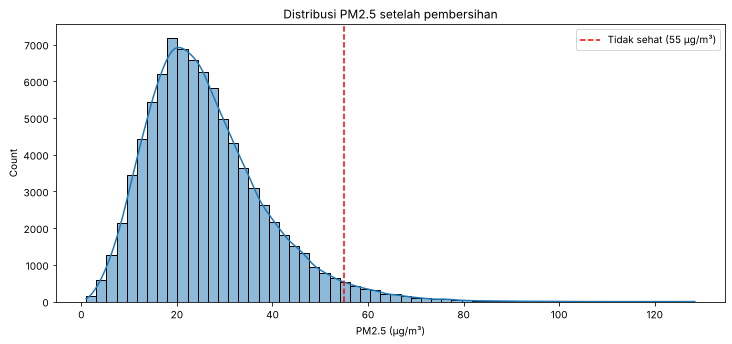

In [23]:
# Kolom bantu waktu dibuat di salinan terpisah agar data/clean.csv tetap ringkas
eda = df_clean.copy()
eda["jam"] = eda["waktu"].dt.hour
eda["hari"] = eda["waktu"].dt.day_name()
eda["bulan"] = eda["waktu"].dt.month

plt.figure(figsize=(12, 5))
sns.histplot(eda["pm25_ugm3"], bins=60, kde=True)
plt.axvline(AMBANG_TIDAK_SEHAT, color="red", linestyle="--", label="Tidak sehat (55 µg/m³)")
plt.title("Distribusi PM2.5 setelah pembersihan")
plt.xlabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

In [24]:
station_stats = eda.groupby("stasiun")["pm25_ugm3"].agg(["count", "mean", "median", "std", "min", "max"])
station_stats["persen_jam_>55"] = eda.groupby("stasiun")["pm25_ugm3"].apply(lambda x: (x > AMBANG_TIDAK_SEHAT).mean() * 100)
station_stats.loc[URUTAN_STASIUN].round(2)

,count,mean,median,std,min,max,persen_jam_>55
stasiun,,,,,,,
Dago,17411,18.87,18.0,7.91,1.0,59.8,0.04
Soekarno-Hatta,17383,34.59,32.8,14.74,1.5,128.4,9.30
Cibeureum,17250,28.58,27.1,12.03,1.4,95.1,2.87
Antapani,17408,25.28,24.0,10.69,1.3,86.2,1.23
Ujungberung,17398,22.94,22.1,9.26,1.2,78.0,0.37


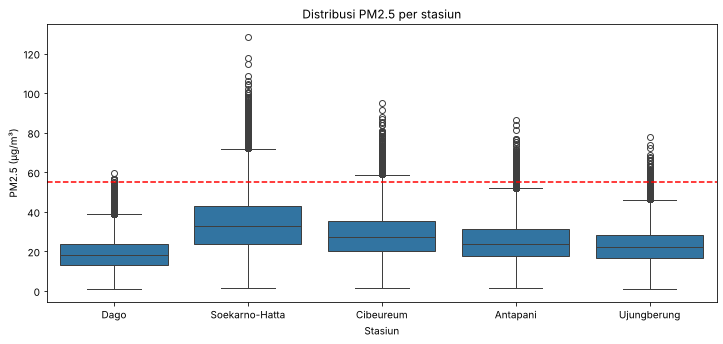

In [25]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=eda, x="stasiun", y="pm25_ugm3", order=URUTAN_STASIUN)
plt.axhline(AMBANG_TIDAK_SEHAT, color="red", linestyle="--")
plt.title("Distribusi PM2.5 per stasiun")
plt.xlabel("Stasiun")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

**Pembahasan Bagian 4.** Setelah dibersihkan, PM2.5 berkisar 1–128 µg/m³ dengan median sekitar 24 µg/m³. Perbedaan antarstasiun besar:

- **Soekarno-Hatta** paling tercemar, dengan rata-rata 34,6 µg/m³. Sebanyak **9,3%** jamnya berada di atas 55 µg/m³ (kategori tidak sehat).
- **Dago** paling bersih, dengan rata-rata 18,9 µg/m³. Hanya 0,04% jamnya melewati 55.

Karena itu, **stasiun harus menjadi fitur**. Kejadian "tidak sehat" juga sangat terkonsentrasi di Soekarno-Hatta dan Cibeureum, sehingga kemampuan peringatan model pada dasarnya diuji di dua stasiun itu.

## 5. Temporal Analysis

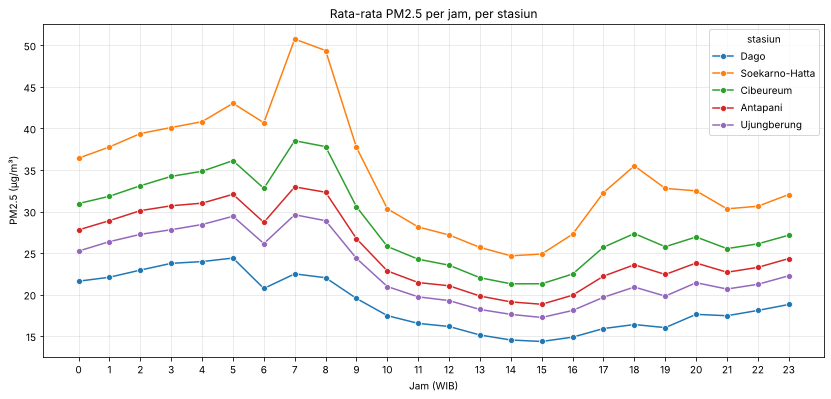

In [26]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=eda, x="jam", y="pm25_ugm3", hue="stasiun", hue_order=URUTAN_STASIUN,
             estimator="mean", errorbar=None, marker="o")
plt.title("Rata-rata PM2.5 per jam, per stasiun")
plt.xlabel("Jam (WIB)")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

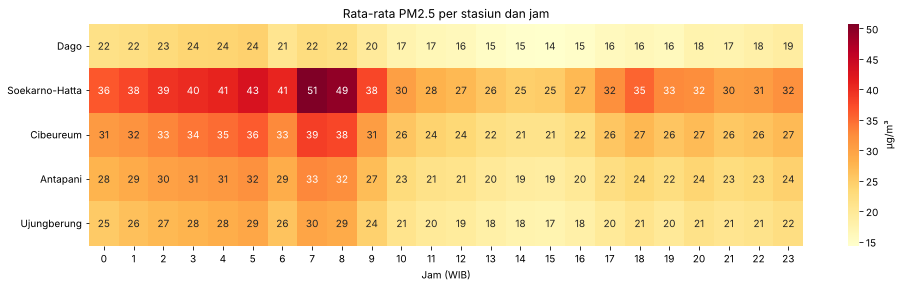

In [27]:
station_hour = eda.pivot_table(index="stasiun", columns="jam", values="pm25_ugm3", aggfunc="mean").loc[URUTAN_STASIUN]
plt.figure(figsize=(16, 4))
sns.heatmap(station_hour, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "µg/m³"})
plt.title("Rata-rata PM2.5 per stasiun dan jam")
plt.xlabel("Jam (WIB)")
plt.ylabel("")
plt.show()

rata-rata per hari:
hari
Monday       26.4
Tuesday      26.4
Wednesday    26.1
Thursday     26.1
Friday       26.3
Saturday     25.9
Sunday       25.2
Name: pm25_ugm3, dtype: float64

rata-rata per bulan:
bulan
1     21.1
2     20.8
3     20.9
4     20.8
5     25.5
6     32.6
7     31.8
8     32.4
9     32.1
10    32.6
11    20.5
12    21.0
Name: pm25_ugm3, dtype: float64


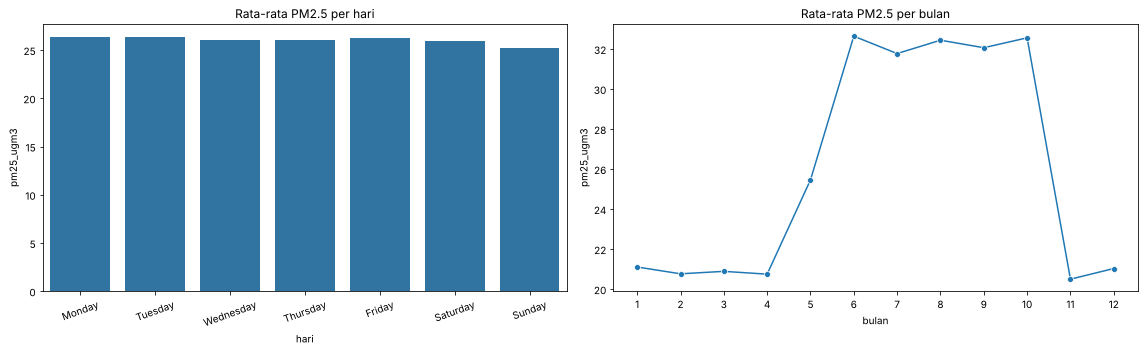

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(data=eda, x="hari", y="pm25_ugm3", order=day_order, errorbar=None, ax=axes[0])
axes[0].set_title("Rata-rata PM2.5 per hari")
axes[0].tick_params(axis="x", rotation=20)
sns.lineplot(data=eda, x="bulan", y="pm25_ugm3", estimator="mean", errorbar=None, marker="o", ax=axes[1])
axes[1].set_title("Rata-rata PM2.5 per bulan")
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

print("rata-rata per hari:"); print(eda.groupby("hari")["pm25_ugm3"].mean().loc[day_order].round(1))
print("\nrata-rata per bulan:"); print(eda.groupby("bulan")["pm25_ugm3"].mean().round(1))

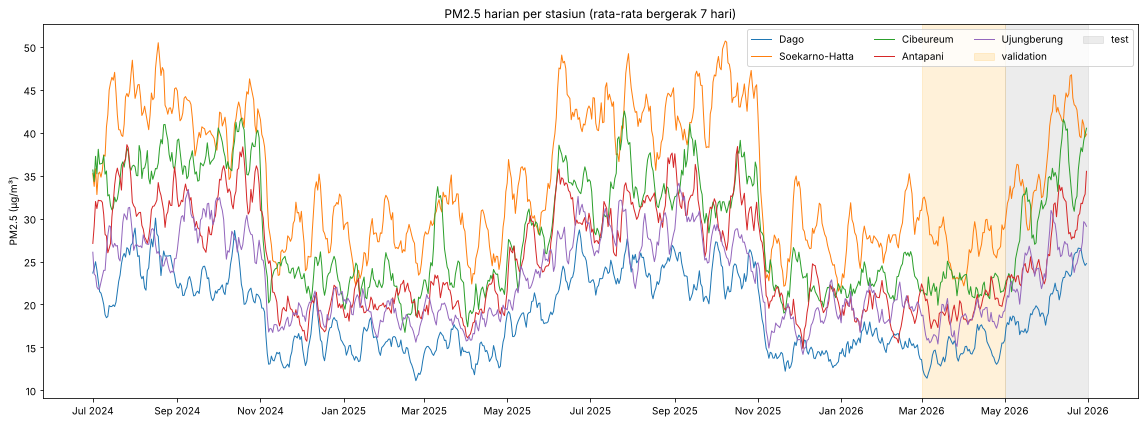

In [29]:
harian = eda.set_index("waktu").groupby("stasiun")["pm25_ugm3"].resample("D").mean().unstack(0)
plt.figure(figsize=(16, 6))
for st in URUTAN_STASIUN:
    plt.plot(harian.index, harian[st].rolling(7, min_periods=1).mean(), linewidth=1, label=st)
plt.axvspan(pd.Timestamp("2026-03-01"), pd.Timestamp("2026-05-01"), color="orange", alpha=0.15, label="validation")
plt.axvspan(pd.Timestamp("2026-05-01"), pd.Timestamp("2026-07-01"), color="grey", alpha=0.15, label="test")
plt.title("PM2.5 harian per stasiun (rata-rata bergerak 7 hari)")
plt.ylabel("PM2.5 (µg/m³)")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.legend(ncol=4)
plt.tight_layout()
plt.show()

**Pembahasan Bagian 5.** Ada tiga pola waktu yang jelas.

**Pola harian.** Puncaknya pagi hari sekitar **pukul 07.00** (Soekarno-Hatta sekitar 51 µg/m³). PM2.5 turun ke titik terendah sekitar **pukul 14–15** (Soekarno-Hatta sekitar 25 µg/m³), lalu naik lagi di malam hari sekitar pukul 19–20. Polanya konsisten di semua stasiun dan masuk akal secara fisik: lalu lintas pagi bertemu udara yang belum tercampur, lalu siang hari udara tercampur ke atas. Jadi **jam** adalah fitur penting, sebaiknya dikodekan siklik (sin/cos), karena prakiraan pukul 15 untuk pukul 18 berbeda polanya dengan prakiraan pukul 04 untuk pukul 07.

**Pola musiman.** Perbedaannya kuat: Juni–Oktober (musim kemarau) rata-ratanya sekitar **32 µg/m³**, sedangkan November–April sekitar **21 µg/m³**. Konsekuensinya penting untuk evaluasi. Periode *validation* (Maret–April 2026) jatuh di musim bersih, sehingga jam di atas 55 sangat sedikit. Periode *test* (Mei–Juni 2026) adalah awal musim kemarau. Kinerja di *validation* bisa jadi tidak sepenuhnya mewakili *test*.

**Pola mingguan.** Lemah: Minggu hanya sekitar 1 µg/m³ lebih rendah daripada hari kerja.

## 6. Multivariate Analysis

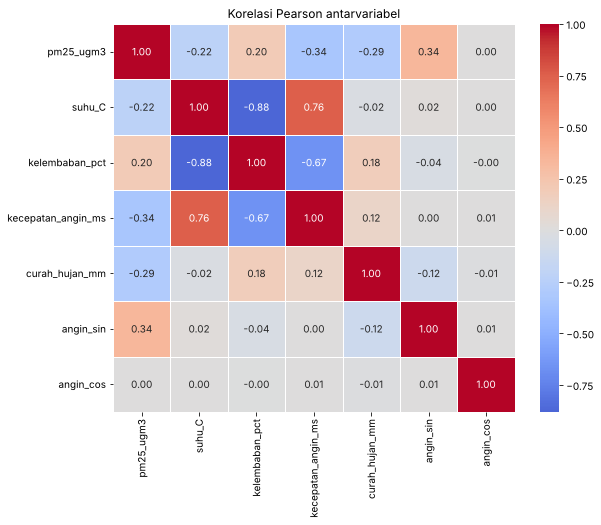

In [30]:
angle_rad = np.deg2rad(eda["arah_angin_deg"])
eda["angin_sin"] = np.sin(angle_rad)   # arah 0° dan 360° jadi sama, tidak berjauhan
eda["angin_cos"] = np.cos(angle_rad)

kolom_korelasi = ["pm25_ugm3", "suhu_C", "kelembaban_pct", "kecepatan_angin_ms",
                  "curah_hujan_mm", "angin_sin", "angin_cos"]
plt.figure(figsize=(9, 7))
sns.heatmap(eda[kolom_korelasi].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Korelasi Pearson antarvariabel")
plt.show()

rata-rata PM2.5 saat hujan    : 15.3
rata-rata PM2.5 saat tidak hujan: 27.3


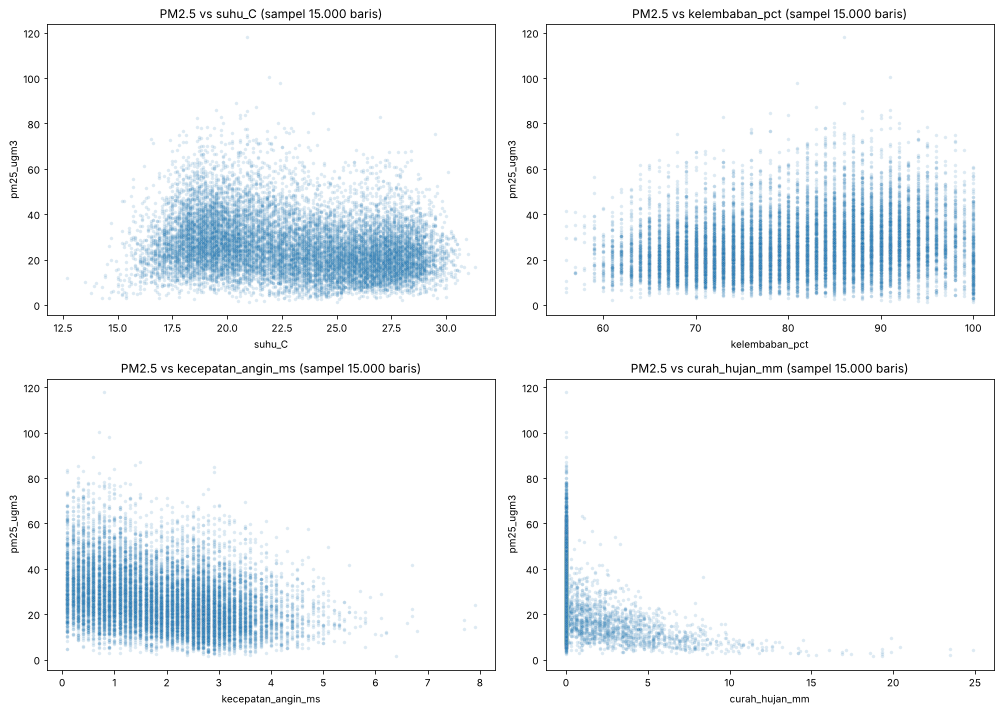

In [31]:
sampel = eda.sample(15000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, fitur in zip(axes.flatten(), ["suhu_C", "kelembaban_pct", "kecepatan_angin_ms", "curah_hujan_mm"]):
    sns.scatterplot(data=sampel, x=fitur, y="pm25_ugm3", alpha=0.15, s=12, ax=ax)
    ax.set_title(f"PM2.5 vs {fitur} (sampel 15.000 baris)")
plt.tight_layout()
plt.show()

hujan = eda["curah_hujan_mm"] > 0
print("rata-rata PM2.5 saat hujan    :", round(eda.loc[hujan, "pm25_ugm3"].mean(), 1))
print("rata-rata PM2.5 saat tidak hujan:", round(eda.loc[~hujan, "pm25_ugm3"].mean(), 1))

**Pembahasan Bagian 6.** Korelasi linear dengan cuaca tergolong sedang:

- Kecepatan angin −0,34: angin kencang mengencerkan polutan.
- Curah hujan −0,29: rata-rata PM2.5 saat hujan 15,3 µg/m³, dibandingkan 27,3 µg/m³ saat tidak hujan (hujan "mencuci" udara).
- Suhu −0,22 dan kelembapan +0,20. Keduanya sebagian besar mengikuti pola harian, karena pagi hari dingin, lembap, dan tercemar.

Arah angin baru berarti setelah diubah menjadi sin/cos. Komponen `angin_sin` berkorelasi +0,34, artinya angin dari arah **timur** cenderung membawa PM2.5 lebih tinggi, sedangkan komponen utara-selatan (`angin_cos`) hampir tidak berpengaruh. Angka mentah 0–360° tidak boleh dipakai langsung, karena 1° dan 359° sebenarnya hampir sama arahnya.

## 7. Time-Series Analysis

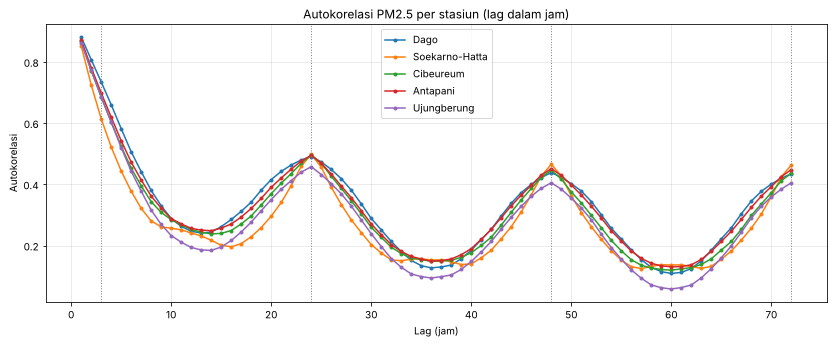

,Antapani,Cibeureum,Dago,Soekarno-Hatta,Ujungberung
1,0.872,0.868,0.881,0.852,0.863
3,0.698,0.686,0.735,0.614,0.686
6,0.473,0.453,0.506,0.377,0.442
12,0.256,0.253,0.247,0.241,0.194
24,0.495,0.496,0.491,0.498,0.458


In [32]:
# Autokorelasi dihitung di grid per jam yang lengkap (jam hilang menjadi NaN),
# sehingga lag k benar-benar berarti k jam, bukan k baris.
lags = range(1, 73)
acf = {}
for st, g in eda.groupby("stasiun"):
    seri = g.set_index("waktu")["pm25_ugm3"].asfreq("h")
    acf[st] = [seri.autocorr(lag) for lag in lags]
acf = pd.DataFrame(acf, index=lags)

plt.figure(figsize=(14, 5))
for st in URUTAN_STASIUN:
    plt.plot(acf.index, acf[st], marker=".", label=st)
for x in (3, 24, 48, 72):
    plt.axvline(x, color="grey", linestyle=":", linewidth=1)
plt.title("Autokorelasi PM2.5 per stasiun (lag dalam jam)")
plt.xlabel("Lag (jam)")
plt.ylabel("Autokorelasi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

acf.loc[[1, 3, 6, 12, 24]].round(3)

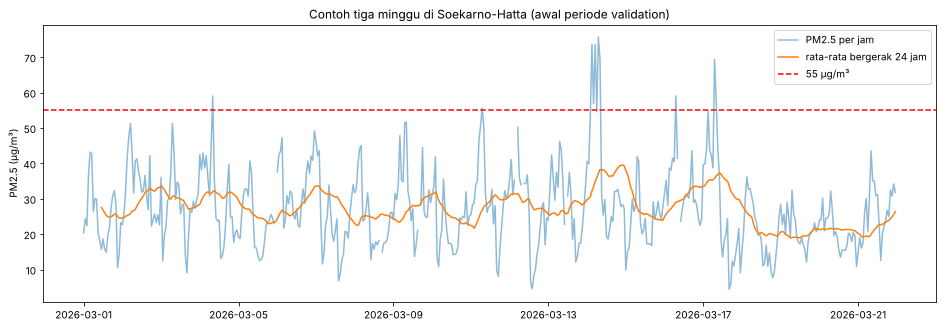

In [33]:
contoh = eda[eda["stasiun"] == "Soekarno-Hatta"].set_index("waktu")["pm25_ugm3"].asfreq("h")
contoh = contoh["2026-03-01":"2026-03-21"]
plt.figure(figsize=(16, 5))
plt.plot(contoh.index, contoh, alpha=0.5, label="PM2.5 per jam")
plt.plot(contoh.index, contoh.rolling(24, min_periods=12).mean(), label="rata-rata bergerak 24 jam")
plt.axhline(AMBANG_TIDAK_SEHAT, color="red", linestyle="--", label="55 µg/m³")
plt.title("Contoh tiga minggu di Soekarno-Hatta (awal periode validation)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

**Pembahasan Bagian 7.** Autokorelasi PM2.5 sangat tinggi di lag 1 jam (0,85–0,88), lalu turun di lag 3 jam (0,61–0,74). Itulah sebabnya *baseline persistence* sudah cukup kuat.

Autokorelasi kemudian **naik lagi ke sekitar 0,5 pada lag 24 jam**, lebih tinggi daripada lag 12 jam (sekitar 0,25). Artinya, nilai **kemarin pada jam yang sama** (lebih tepatnya 21 jam sebelum jam saat ini, yaitu 24 jam sebelum jam target) membawa informasi yang tidak dimiliki *persistence*.

Soekarno-Hatta memiliki autokorelasi lag 3 terendah (0,61), sehingga stasiun ini paling sulit diprakirakan oleh *persistence*.

Kandidat fitur untuk tahap pemodelan:

- **Lag:** PM2.5 jam ini, 1, 2, 3, dan 24 jam lalu.
- **Statistik bergerak:** rata-rata 3/6/24 jam terakhir.
- **Tren:** selisih jam ini dengan 1 jam lalu.
- **Cuaca saat ini.**
- **Waktu:** jam dan bulan.

Semua fitur ini memakai informasi sampai jam saat ini, sesuai aturan brief.

## 8. Target, Pembagian Data, dan Baseline

Target dibuat dengan mencocokkan **waktu tepat** `waktu + 3 jam` di stasiun yang sama. Jika jam itu tidak ada atau
PM2.5-nya kosong, targetnya kosong dan baris tersebut tidak dipakai.

In [34]:
future_target = df_clean[["waktu", "stasiun", "pm25_ugm3"]].rename(
    columns={"waktu": "target_time", "pm25_ugm3": "target_pm25"})

df_model = df_clean.copy()
df_model["target_time"] = df_model["waktu"] + pd.Timedelta(hours=3)
df_model = df_model.merge(future_target, on=["target_time", "stasiun"], how="left", validate="many_to_one")

print("baris:", len(df_model))
print("target kosong:", df_model["target_pm25"].isna().sum(),
      f"({df_model['target_pm25'].isna().mean() * 100:.2f}%)")
df_model[["waktu", "target_time", "stasiun", "pm25_ugm3", "target_pm25"]].head()

baris: 87252
target kosong: 762 (0.87%)


,waktu,target_time,stasiun,pm25_ugm3,target_pm25
0,2024-07-01 00:00:00,2024-07-01 03:00:00,Antapani,34.9,34.2
1,2024-07-01 01:00:00,2024-07-01 04:00:00,Antapani,33.1,37.6
2,2024-07-01 02:00:00,2024-07-01 05:00:00,Antapani,38.2,25.7
3,2024-07-01 03:00:00,2024-07-01 06:00:00,Antapani,34.2,30.7
4,2024-07-01 04:00:00,2024-07-01 07:00:00,Antapani,37.6,30.3


In [35]:
# Pembagian berdasarkan waktu target, sesuai contoh di brief
train_end = pd.Timestamp("2026-03-01")
validation_end = pd.Timestamp("2026-05-01")
test_end = pd.Timestamp("2026-07-01")

df_model_valid = df_model.dropna(subset=["target_pm25"]).copy()
train_df = df_model_valid[df_model_valid["target_time"] < train_end].copy()
val_df = df_model_valid[(df_model_valid["target_time"] >= train_end) &
                        (df_model_valid["target_time"] < validation_end)].copy()
test_df = df_model_valid[(df_model_valid["target_time"] >= validation_end) &
                         (df_model_valid["target_time"] < test_end)].copy()

pd.DataFrame({
    "baris": [len(train_df), len(val_df), len(test_df)],
    "awal_target": [d["target_time"].min() for d in (train_df, val_df, test_df)],
    "akhir_target": [d["target_time"].max() for d in (train_df, val_df, test_df)],
}, index=["train", "validation", "test"])

,baris,awal_target,akhir_target
train,71988,2024-07-01 03:00:00,2026-02-28 23:00:00
validation,7258,2026-03-01 00:00:00,2026-04-30 23:00:00
test,7244,2026-05-01 00:00:00,2026-06-30 23:00:00


**Catatan:** untuk data *test* hanya ukuran dan rentang waktunya yang ditampilkan. Isi target dan kinerja
*baseline* di *test* sengaja tidak dilihat sampai model final dipilih.

In [36]:
from sklearn.metrics import mean_absolute_error

def evaluasi(y_true, y_pred, nama):
    """MAE dan kemampuan memperingatkan jam dengan PM2.5 > 55 µg/m³."""
    aktual = y_true > AMBANG_TIDAK_SEHAT
    tebak = y_pred > AMBANG_TIDAK_SEHAT
    tp = (aktual & tebak).sum()
    return {
        "data": nama,
        "sampel": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "jam_>55": int(aktual.sum()),
        "recall_>55": tp / aktual.sum() if aktual.sum() else np.nan,
        "precision_>55": tp / tebak.sum() if tebak.sum() else np.nan,
    }

def baseline_persistence(data):
    # Prediksi = PM2.5 jam ini. Baris dengan PM2.5 jam ini kosong tidak bisa diprediksi persistence.
    ada = data.dropna(subset=["pm25_ugm3"])
    return ada["target_pm25"], ada["pm25_ugm3"]

baseline_results = pd.DataFrame([
    evaluasi(*baseline_persistence(train_df), "train"),
    evaluasi(*baseline_persistence(val_df), "validation"),
])
baseline_results.round(4)

,data,sampel,MAE,jam_>55,recall_>55,precision_>55
0,train,71772,6.8157,2113,0.3559,0.3561
1,validation,7238,6.2349,43,0.1860,0.1860


**Pembahasan Bagian 8.** *Baseline persistence* menghasilkan **MAE 6,23 µg/m³ pada *validation*** (6,82 pada *train*). Model final harus mengalahkan angka ini.

Dalam hal peringatan, *persistence* hanya menangkap **18,6%** jam tidak sehat di *validation*. Wajar: persistence baru memperingatkan jika udara *sudah* buruk, padahal klien justru ingin peringatan *sebelum* udara memburuk.

**Peringatan untuk interpretasi:** *validation* hanya memiliki **43 jam** dengan PM2.5 di atas 55. Akibatnya, *recall* sangat sensitif, karena selisih satu jam saja menggeser *recall* sekitar 2,3 poin persen. Karena itu, laporkan *recall* bersama jumlah kejadiannya, dan pertimbangkan juga melihat *recall* di *train* dengan validasi silang berbasis waktu.

## 9. Ringkasan dan Langkah Berikutnya

**Pembersihan data** (rinciannya ada di tabel bagian 3.7):

- Nama stasiun dinormalisasi.
- 398 duplikat dihapus.
- **2.196 baris Soekarno-Hatta yang tercatat dalam UTC digeser +7 jam.**
- Nilai -999 dan 0 pada PM2.5 diubah menjadi NaN.
- Jam yang hilang tidak diinterpolasi.

Hasilnya disimpan di `data/clean.csv` (87.252 baris).

**Temuan EDA yang paling berpengaruh terhadap model:**

1. **Pola harian yang kuat**: puncak sekitar pukul 07, titik terendah sekitar pukul 14–15. Fitur jam wajib ada, dan autokorelasi lag 24 menunjukkan nilai "kemarin jam yang sama" berguna.
2. **Perbedaan antarstasiun yang besar**: Soekarno-Hatta hampir dua kali Dago dan menyumbang sebagian besar jam tidak sehat.
3. **Musim kemarau (Juni–Oktober) jauh lebih tercemar**, sedangkan *validation* jatuh di musim bersih. Kinerja peringatan di *validation* harus dibaca hati-hati.

**Baseline wajib:** *persistence*, dengan MAE *validation* **6,23 µg/m³** dan *recall* >55 sebesar 18,6%.

**Langkah berikutnya:**

- Buat fitur di `src/features.py` di atas grid per jam yang lengkap per stasiun (`asfreq("h")`), dengan fitur kosong diisi `ffill` maksimal 2 jam.
- Latih beberapa model, misalnya regresi linear dan *gradient boosting*, lalu pilih yang terbaik berdasarkan MAE *validation*.
- Buka data *test* sekali di akhir untuk *baseline* dan model final sekaligus.